In [3]:
import sys
import os

import h5py

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../import/'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [4]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/fly-2023-schaffner/data_exploration/manifold/../../import/utils/train_utils.py'>

In [5]:
# selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']
selection_bhl = ['undefined', 'quiescence', 'ab_bending', 'grooming_b', 'grooming_f', 'running']

dims = 3

read_ids = [20]
plot_id = 20

In [6]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffner')
(file_ids, filenames,
 traces,
 ball_motions,
 behavioral_states) = read_utils.get_data(path, read_ids)

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces,
												 n_pc=dims)

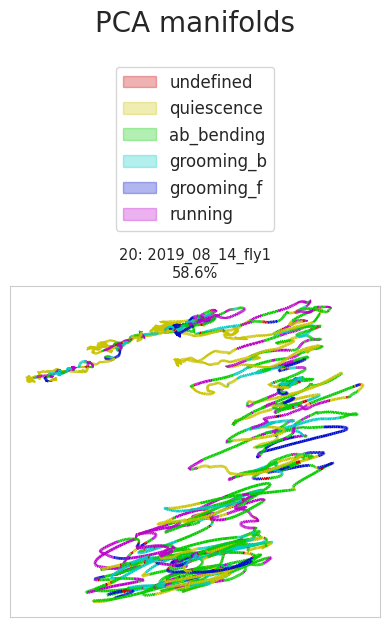

58.6%


In [8]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, behavioral_states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=2.5)

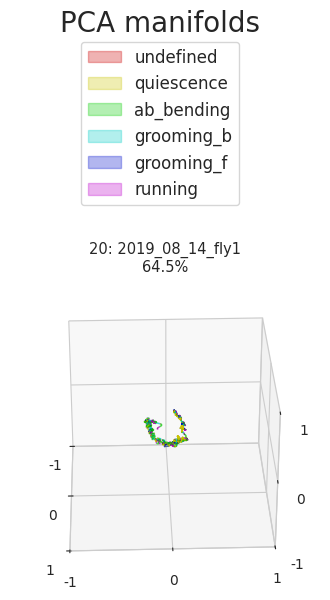

64.5%


In [9]:
plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
								 modes_manifold, behavioral_states,
								 [vx[:3] for vx in vars_expl_mans], None,
								 animate=True, n_plots=1,
								 titles=['PCA manifolds'] * len(file_ids), save_name=f'{dims}-dim-PCA_3d')